In [2]:
pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score

df = pd.read_csv('CC_Customer_Dataset.csv')

# Menampilkan 5 data pertama
df.head()

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


In [5]:
# Melihat informasi dataset
print("Shape:", df.shape)

print("\nKolom dataset:")
print(df.columns.tolist())

print("\nInformasi dataset:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

Shape: (660, 7)

Kolom dataset:
['Sl_No', 'Customer Key', 'Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']

Informasi dataset:
<class 'pandas.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB

Missing values:
Sl_No                  0
Customer Key           0
Avg_Credit_Limit       0
Total_Credit_Cards     0
Total_visits_bank      0
Total_visits_online    0
Total_calls_made       0
dtype: int64


In [6]:
# Menghapus kolom identitas jika tersedia
id_columns = ['Sl_No', 'Customer Key']

df_model = df.drop(
    columns=[col for col in id_columns if col in df.columns]
)

# Mengambil seluruh variabel numerik
X = df_model.select_dtypes(include=np.number).copy()

# Mengatasi missing values jika ada
X = X.fillna(X.median())

print("Variabel yang digunakan:")
print(X.columns.tolist())

print("\nJumlah variabel:", X.shape[1])

Variabel yang digunakan:
['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']

Jumlah variabel: 5


In [7]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Standardisasi berhasil!")
print("Ukuran data:", X_scaled.shape)

Standardisasi berhasil!
Ukuran data: (660, 5)


In [8]:
silhouette_scores = []

for k in range(2, 11):
    model = AgglomerativeClustering(
        n_clusters=k,
        linkage='ward'
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    silhouette_scores.append(score)

    print(f"Jumlah Cluster: {k}, Silhouette Score: {score:.4f}")

# Menentukan jumlah cluster terbaik
best_k = range(2, 11)[np.argmax(silhouette_scores)]

print("\nJumlah cluster terbaik:", best_k)

Jumlah Cluster: 2, Silhouette Score: 0.4177
Jumlah Cluster: 3, Silhouette Score: 0.5148
Jumlah Cluster: 4, Silhouette Score: 0.3481
Jumlah Cluster: 5, Silhouette Score: 0.2569
Jumlah Cluster: 6, Silhouette Score: 0.2268
Jumlah Cluster: 7, Silhouette Score: 0.2163
Jumlah Cluster: 8, Silhouette Score: 0.2187
Jumlah Cluster: 9, Silhouette Score: 0.1953
Jumlah Cluster: 10, Silhouette Score: 0.1931

Jumlah cluster terbaik: 3


In [9]:
model = AgglomerativeClustering(
    n_clusters=best_k,
    linkage='ward'
)

clusters = model.fit_predict(X_scaled)

# Menambahkan hasil cluster ke dataset
df['Cluster'] = clusters

print(df.head())

   Sl_No  Customer Key  Avg_Credit_Limit  Total_Credit_Cards  \
0      1         87073            100000                   2   
1      2         38414             50000                   3   
2      3         17341             50000                   7   
3      4         40496             30000                   5   
4      5         47437            100000                   6   

   Total_visits_bank  Total_visits_online  Total_calls_made  Cluster  
0                  1                    1                 0        0  
1                  0                   10                 9        1  
2                  1                    3                 4        0  
3                  1                    1                 4        0  
4                  0                   12                 3        2  


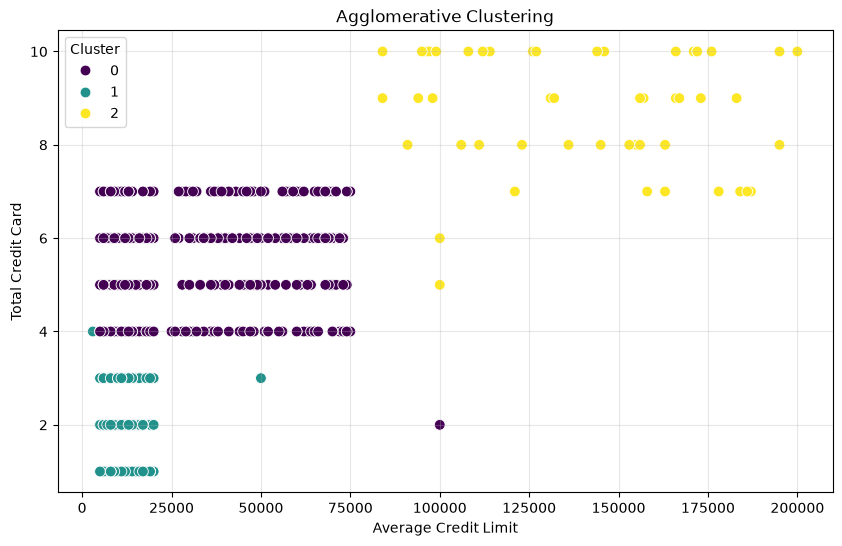

In [10]:
# Mencari nama kolom berdasarkan beberapa kemungkinan
def find_column(candidates, columns):
    for candidate in candidates:
        for col in columns:
            if col.lower().replace('_', '').replace(' ', '') == candidate.lower().replace('_', '').replace(' ', ''):
                return col
    raise ValueError(f"Kolom tidak ditemukan: {candidates}")

x_col = find_column(
    ['Avg_Credit_Limit'],
    df.columns
)

y_col = find_column(
    ['Total_credit_card', 'Total_Credit_Cards'],
    df.columns
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x=x_col,
    y=y_col,
    hue='Cluster',
    palette='viridis',
    s=60
)

plt.title('Agglomerative Clustering')
plt.xlabel('Average Credit Limit')
plt.ylabel('Total Credit Card')
plt.legend(title='Cluster')
plt.grid(alpha=0.3)
plt.show()

In [11]:
# Menghitung Silhouette Score
sil_score = silhouette_score(X_scaled, clusters)

# Menghitung Davies-Bouldin Index
dbi_score = davies_bouldin_score(X_scaled, clusters)

print("Hasil Evaluasi Agglomerative Clustering")
print("---------------------------------------")
print(f"Jumlah Cluster       : {best_k}")
print(f"Silhouette Score     : {sil_score:.4f}")
print(f"Davies-Bouldin Index : {dbi_score:.4f}")

Hasil Evaluasi Agglomerative Clustering
---------------------------------------
Jumlah Cluster       : 3
Silhouette Score     : 0.5148
Davies-Bouldin Index : 0.6810


In [12]:
cluster_counts = df['Cluster'].value_counts().sort_index()

print("Jumlah anggota setiap cluster:")
print(cluster_counts)

Jumlah anggota setiap cluster:
Cluster
0    385
1    225
2     50
Name: count, dtype: int64
